<a href="https://colab.research.google.com/github/AnjanaVP231/ML/blob/main/lab3DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Decision_Tree_Dataset.xlsx - Decision_Tree_Dataset.csv to Decision_Tree_Dataset.xlsx - Decision_Tree_Dataset (2).csv
First 10 records:
   Study_Hours_Per_Day  Attendance_Percent  Assignment_Score_Percent  \
0                    1                  55                        42   
1                    2                  60                        48   
2                    2                  68                        55   
3                    3                  58                        50   
4                    3                  72                        60   
5                    4                  65                        62   
6                    4                  75                        68   
7                    5                  62                        70   
8                    5                  78                        72   
9                    5                  85                        80   

   Previous_Marks_Percent Result  
0                      38   Fa

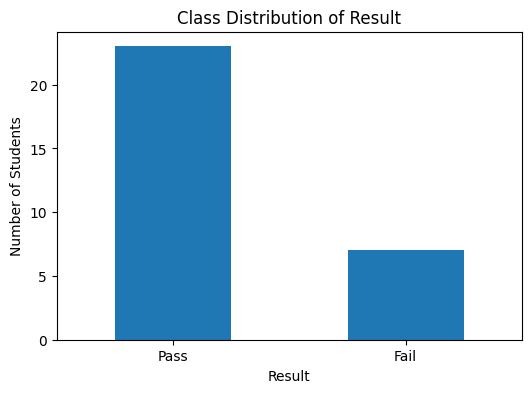


TASK 2

Entropy of complete dataset:
0.783776947484701

Gini Impurity of complete dataset:
0.35777777777777775

Selected feature:
Study_Hours_Per_Day

Candidate thresholds:
[np.float64(1.5), np.float64(2.5), np.float64(3.5), np.float64(4.5), np.float64(5.5), np.float64(6.5), np.float64(7.5), np.float64(8.5), np.float64(9.5), np.float64(10.5), np.float64(11.5)]

Information Gain:
Threshold: 1.5 Information Gain: 0.07278531864932247
Threshold: 2.5 Information Gain: 0.23910902851462246
Threshold: 3.5 Information Gain: 0.4486276223161403
Threshold: 4.5 Information Gain: 0.447905653172466
Threshold: 5.5 Information Gain: 0.4900133144078034
Threshold: 6.5 Information Gain: 0.3522950515812332
Threshold: 7.5 Information Gain: 0.25647059639750236
Threshold: 8.5 Information Gain: 0.1824573377390003
Threshold: 9.5 Information Gain: 0.12202187343504989
Threshold: 10.5 Information Gain: 0.0709012720179254
Threshold: 11.5 Information Gain: 0.026584031322843593

Best split threshold:
5.5

Best Infor

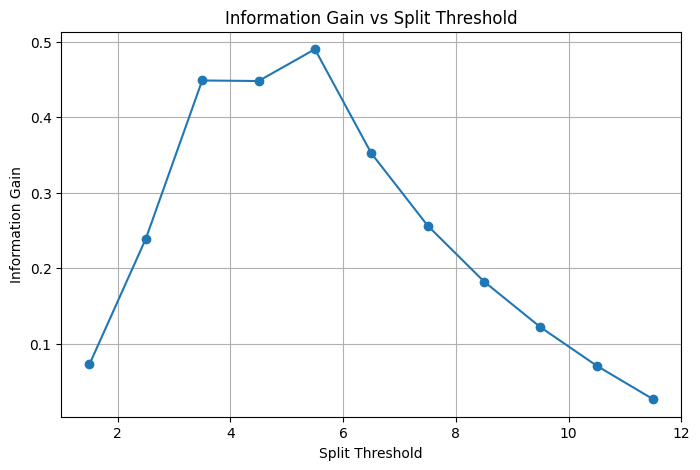


TASK 3

Root Node:
Study_Hours_Per_Day <= 5.5

Left Branch:
Number of records: 10
Class distribution:
Result
Fail    7
Pass    3
Name: count, dtype: int64

Right Branch:
Number of records: 20
Class distribution:
Result
Pass    20
Name: count, dtype: int64

Recursive splitting:

 Left subset
Best next split: Attendance_Percent <= 73.5
Information Gain: 0.8812908992306927
Left child class: Fail
Right child class: Pass

 Right subset
Leaf Node: Pass

Decision Tree using criterion='gini' trained successfully.


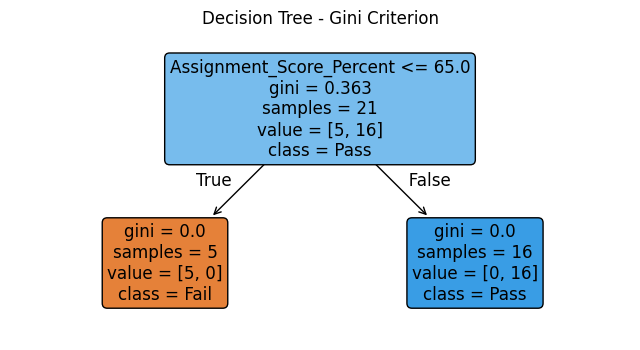


TASK 4

Confusion Matrix:
[[1 1]
 [0 7]]


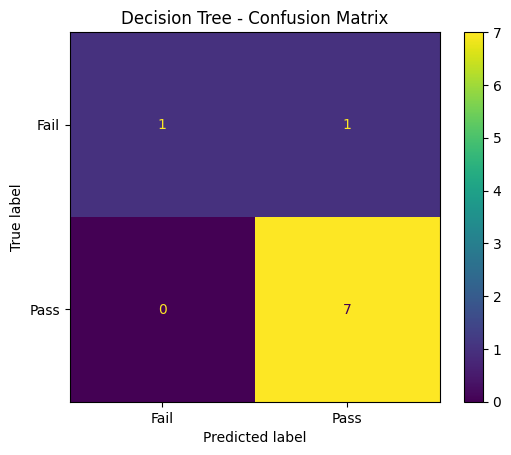


Accuracy : 0.8888888888888888
Precision: 0.875
Recall   : 1.0
F1-score : 0.9333333333333333

TASK 5


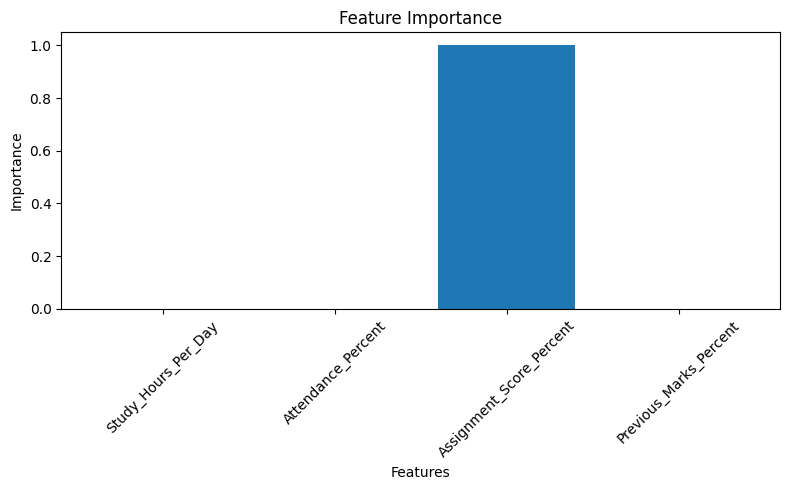

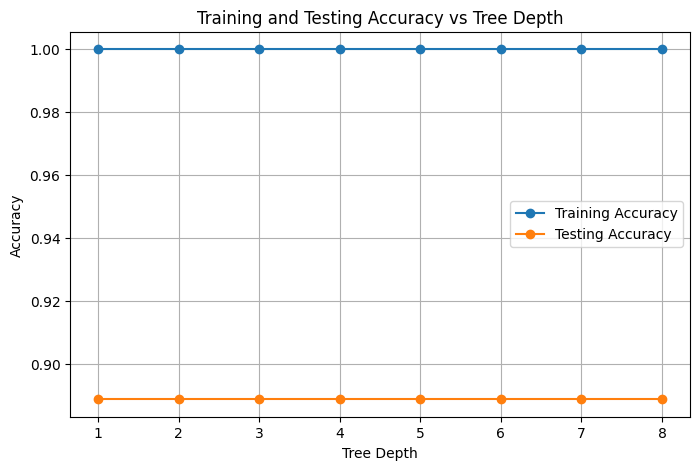


Tree Depth Results:
Depth: 1 Training Accuracy: 1.0 Testing Accuracy: 0.8888888888888888
Depth: 2 Training Accuracy: 1.0 Testing Accuracy: 0.8888888888888888
Depth: 3 Training Accuracy: 1.0 Testing Accuracy: 0.8888888888888888
Depth: 4 Training Accuracy: 1.0 Testing Accuracy: 0.8888888888888888
Depth: 5 Training Accuracy: 1.0 Testing Accuracy: 0.8888888888888888
Depth: 6 Training Accuracy: 1.0 Testing Accuracy: 0.8888888888888888
Depth: 7 Training Accuracy: 1.0 Testing Accuracy: 0.8888888888888888
Depth: 8 Training Accuracy: 1.0 Testing Accuracy: 0.8888888888888888

Effect of min_samples_split:
min_samples_split = 2 Testing Accuracy = 0.8888888888888888
min_samples_split = 5 Testing Accuracy = 0.8888888888888888
min_samples_split = 10 Testing Accuracy = 0.8888888888888888

Effect of min_samples_leaf:
min_samples_leaf = 1 Testing Accuracy = 0.8888888888888888
min_samples_leaf = 2 Testing Accuracy = 0.8888888888888888
min_samples_leaf = 5 Testing Accuracy = 0.8888888888888888

TASK 6

G

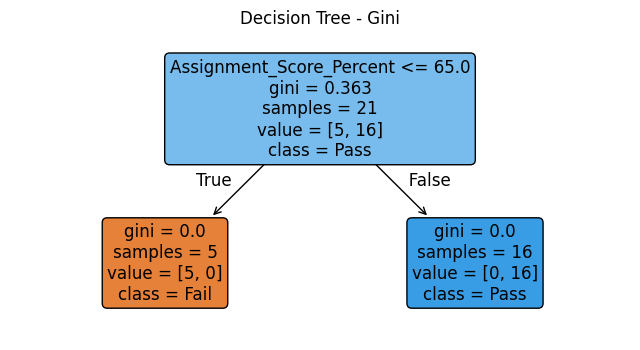

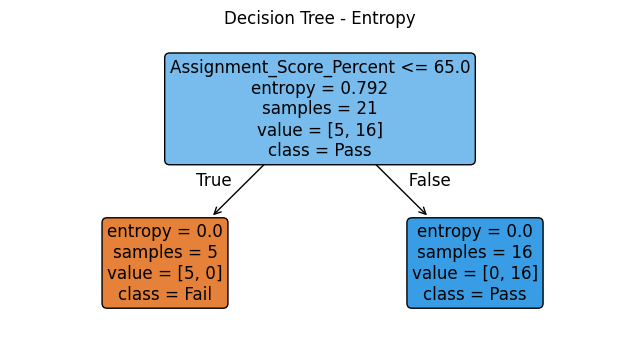


Three New Student Predictions:
Student 1 : Fail
Student 2 : Pass
Student 3 : Pass


In [ ]:
# ============================================================
# LAB 3 - DECISION TREE CLASSIFICATION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# TASK 1 - LOAD AND UNDERSTAND THE DATASET
# ============================================================

uploaded = files.upload()

file = list(uploaded.keys())[0]

df = pd.read_csv(file)

print("First 10 records:")
print(df.head(10))

target = "Result"

X = df.drop(columns=target)
y = df[target]

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print(target)

print("\nClass distribution:")
print(y.value_counts())

plt.figure(figsize=(6, 4))
y.value_counts().plot(kind="bar")
plt.xlabel("Result")
plt.ylabel("Number of Students")
plt.title("Class Distribution of Result")
plt.xticks(rotation=0)
plt.show()


# ============================================================
# TASK 2 - ENTROPY, GINI IMPURITY AND INFORMATION GAIN
# ============================================================

print("\n" + "=" * 60)
print("TASK 2")
print("=" * 60)


# ---------- Entropy of complete dataset ----------

def entropy(data):
    probabilities = data["Result"].value_counts(
        normalize=True
    )

    return -sum(
        p * np.log2(p)
        for p in probabilities
    )


# ---------- Gini impurity of complete dataset ----------

def gini_impurity(data):
    probabilities = data["Result"].value_counts(
        normalize=True
    )

    return 1 - sum(p ** 2 for p in probabilities)


dataset_entropy = entropy(df)
dataset_gini = gini_impurity(df)

print("\nEntropy of complete dataset:")
print(dataset_entropy)

print("\nGini Impurity of complete dataset:")
print(dataset_gini)


# ---------- Select numerical feature ----------

feature = "Study_Hours_Per_Day"

values = sorted(df[feature].unique())

# Candidate thresholds are midpoints
thresholds = [
    (values[i] + values[i + 1]) / 2
    for i in range(len(values) - 1)
]


# ---------- Information Gain ----------

def information_gain(data, feature, threshold):

    left = data[data[feature] <= threshold]
    right = data[data[feature] > threshold]

    if len(left) == 0 or len(right) == 0:
        return 0

    weighted_entropy = (
        (len(left) / len(data)) * entropy(left)
        +
        (len(right) / len(data)) * entropy(right)
    )

    return entropy(data) - weighted_entropy


information_gains = []

for threshold in thresholds:

    gain = information_gain(
        df,
        feature,
        threshold
    )

    information_gains.append(gain)


# ---------- Best split ----------

best_index = np.argmax(information_gains)

best_threshold = thresholds[best_index]
best_gain = information_gains[best_index]

print("\nSelected feature:")
print(feature)

print("\nCandidate thresholds:")
print(thresholds)

print("\nInformation Gain:")
for threshold, gain in zip(
    thresholds,
    information_gains
):
    print(
        "Threshold:",
        threshold,
        "Information Gain:",
        gain
    )

print("\nBest split threshold:")
print(best_threshold)

print("\nBest Information Gain:")
print(best_gain)

print(
    "\nBest split is selected because it gives "
    "the maximum Information Gain."
)


# ---------- Plot Information Gain ----------

plt.figure(figsize=(8, 5))

plt.plot(
    thresholds,
    information_gains,
    marker="o"
)

plt.xlabel("Split Threshold")
plt.ylabel("Information Gain")
plt.title(
    "Information Gain vs Split Threshold"
)

plt.grid()
plt.show()


# ============================================================
# TASK 3 - DECISION TREE CONSTRUCTION
# ============================================================

print("\n" + "=" * 60)
print("TASK 3")
print("=" * 60)


# ---------- Root node ----------

left_subset = df[
    df[feature] <= best_threshold
]

right_subset = df[
    df[feature] > best_threshold
]

print("\nRoot Node:")
print(
    feature,
    "<=",
    best_threshold
)

print("\nLeft Branch:")
print(
    "Number of records:",
    len(left_subset)
)
print(
    "Class distribution:"
)
print(left_subset["Result"].value_counts())

print("\nRight Branch:")
print(
    "Number of records:",
    len(right_subset)
)
print(
    "Class distribution:"
)
print(right_subset["Result"].value_counts())


# ---------- Recursive splitting demonstration ----------

def majority_class(data):
    return data["Result"].mode()[0]


print("\nRecursive splitting:")

for branch_name, subset in [
    ("Left subset", left_subset),
    ("Right subset", right_subset)
]:

    print("\n", branch_name)

    if len(subset["Result"].unique()) == 1:

        print(
            "Leaf Node:",
            subset["Result"].iloc[0]
        )

    else:

        best_feature = None
        best_threshold_sub = None
        best_gain_sub = -1

        for f in X.columns:

            values_sub = sorted(
                subset[f].unique()
            )

            if len(values_sub) < 2:
                continue

            sub_thresholds = [
                (values_sub[i] + values_sub[i + 1]) / 2
                for i in range(len(values_sub) - 1)
            ]

            for t in sub_thresholds:

                gain = information_gain(
                    subset,
                    f,
                    t
                )

                if gain > best_gain_sub:

                    best_gain_sub = gain
                    best_feature = f
                    best_threshold_sub = t

        print(
            "Best next split:",
            best_feature,
            "<=",
            best_threshold_sub
        )

        print(
            "Information Gain:",
            best_gain_sub
        )

        left_child = subset[
            subset[best_feature] <= best_threshold_sub
        ]

        right_child = subset[
            subset[best_feature] > best_threshold_sub
        ]

        print(
            "Left child class:",
            majority_class(left_child)
        )

        print(
            "Right child class:",
            majority_class(right_child)
        )


# ---------- Scikit-learn Decision Tree ----------

X_encoded = pd.get_dummies(
    X,
    columns=X.select_dtypes(
        exclude=np.number
    ).columns
)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

tree_gini = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

tree_gini.fit(
    X_train,
    y_train
)

print("\nDecision Tree using criterion='gini' trained successfully.")


# ---------- Visualize Decision Tree ----------

plt.figure(figsize=(8, 4))

plot_tree(
    tree_gini,
    feature_names=X_encoded.columns,
    class_names=tree_gini.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Gini Criterion")
plt.show()


# ============================================================
# TASK 4 - PREDICTION AND MODEL EVALUATION
# ============================================================

print("\n" + "=" * 60)
print("TASK 4")
print("=" * 60)


# Predict test data
y_pred = tree_gini.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=tree_gini.classes_
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=tree_gini.classes_
)

disp.plot()
plt.title("Decision Tree - Confusion Matrix")
plt.show()


# Evaluation metrics

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label="Pass",
    zero_division=0
)

print("\nAccuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)


# ============================================================
# TASK 5 - FEATURE IMPORTANCE AND TREE COMPLEXITY
# ============================================================

print("\n" + "=" * 60)
print("TASK 5")
print("=" * 60)


# ---------- Feature Importance ----------

importance = tree_gini.feature_importances_

plt.figure(figsize=(8, 5))

plt.bar(
    X_encoded.columns,
    importance
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ---------- Different max_depth values ----------

depths = [1, 2, 3, 4, 5, 6, 7, 8]

training_accuracy = []
testing_accuracy = []

for depth in depths:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    training_accuracy.append(
        accuracy_score(y_train, train_pred)
    )

    testing_accuracy.append(
        accuracy_score(y_test, test_pred)
    )


# Plot training and testing accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    depths,
    training_accuracy,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depths,
    testing_accuracy,
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Tree Depth")
plt.ylabel("Accuracy")
plt.title(
    "Training and Testing Accuracy vs Tree Depth"
)

plt.legend()
plt.grid()
plt.show()


# ---------- Underfitting / Overfitting ----------

print("\nTree Depth Results:")

for i in range(len(depths)):

    print(
        "Depth:",
        depths[i],
        "Training Accuracy:",
        training_accuracy[i],
        "Testing Accuracy:",
        testing_accuracy[i]
    )


# ---------- Effect of min_samples_split ----------

split_values = [2, 5, 10]

print("\nEffect of min_samples_split:")

for value in split_values:

    model = DecisionTreeClassifier(
        criterion="gini",
        min_samples_split=value,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    prediction = model.predict(X_test)

    print(
        "min_samples_split =",
        value,
        "Testing Accuracy =",
        accuracy_score(y_test, prediction)
    )


# ---------- Effect of min_samples_leaf ----------

leaf_values = [1, 2, 5]

print("\nEffect of min_samples_leaf:")

for value in leaf_values:

    model = DecisionTreeClassifier(
        criterion="gini",
        min_samples_leaf=value,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    prediction = model.predict(X_test)

    print(
        "min_samples_leaf =",
        value,
        "Testing Accuracy =",
        accuracy_score(y_test, prediction)
    )


# ============================================================
# TASK 6 - GINI VS ENTROPY AND NEW PREDICTION
# ============================================================

print("\n" + "=" * 60)
print("TASK 6")
print("=" * 60)


# ---------- Gini Tree ----------

gini_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

gini_model.fit(
    X_train,
    y_train
)

gini_prediction = gini_model.predict(X_test)

gini_accuracy = accuracy_score(
    y_test,
    gini_prediction
)


# ---------- Entropy Tree ----------

entropy_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

entropy_model.fit(
    X_train,
    y_train
)

entropy_prediction = entropy_model.predict(X_test)

entropy_accuracy = accuracy_score(
    y_test,
    entropy_prediction
)


# ---------- Compare Testing Performance ----------

comparison = pd.DataFrame({
    "Criterion": [
        "Gini",
        "Entropy"
    ],
    "Testing Accuracy": [
        gini_accuracy,
        entropy_accuracy
    ],
    "Tree Depth": [
        gini_model.get_depth(),
        entropy_model.get_depth()
    ],
    "Number of Leaves": [
        gini_model.get_n_leaves(),
        entropy_model.get_n_leaves()
    ]
})

print("\nGini vs Entropy:")
print(comparison)


# ---------- Tree structures ----------

plt.figure(figsize=(8, 4))

plot_tree(
    gini_model,
    feature_names=X_encoded.columns,
    class_names=gini_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Gini")
plt.show()


plt.figure(figsize=(8, 4))

plot_tree(
    entropy_model,
    feature_names=X_encoded.columns,
    class_names=entropy_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision Tree - Entropy")
plt.show()


# ---------- Three New Students ----------

new_students = pd.DataFrame({
    "Study_Hours_Per_Day": [4, 7, 10],
    "Attendance_Percent": [70, 85, 95],
    "Assignment_Score_Percent": [65, 80, 95],
    "Previous_Marks_Percent": [55, 70, 85]
})

new_students_encoded = pd.DataFrame(
    0,
    index=new_students.index,
    columns=X_encoded.columns
)

for column in new_students.columns:
    if column in new_students_encoded.columns:
        new_students_encoded[column] = new_students[column]

new_predictions = gini_model.predict(
    new_students_encoded
)

print("\nThree New Student Predictions:")

for i in range(3):

    print(
        "Student",
        i + 1,
        ":",
        new_predictions[i]
    )